In [260]:
import pandas as pd 

df = pd.read_excel("premiums_with_life_style.xlsx")
df.shape

(10000, 15)

In [261]:
df.columns

Index(['Age', 'Gender', 'Region', 'Marital_status', 'Physical_Activity',
       'Stress_Level', 'Number Of Dependants', 'BMI_Category',
       'Smoking_Status', 'Employment_Status', 'Income_Level', 'Income_Lakhs',
       'Medical History', 'Insurance_Plan', 'Annual_Premium_Amount'],
      dtype='object')

In [262]:
df.columns = df.columns.str.replace(' ', '_').str.lower()
df.columns

Index(['age', 'gender', 'region', 'marital_status', 'physical_activity',
       'stress_level', 'number_of_dependants', 'bmi_category',
       'smoking_status', 'employment_status', 'income_level', 'income_lakhs',
       'medical_history', 'insurance_plan', 'annual_premium_amount'],
      dtype='object')

In [263]:
df.isnull().sum()

age                       0
gender                    0
region                    0
marital_status            0
physical_activity         0
stress_level              0
number_of_dependants      0
bmi_category              0
smoking_status            9
employment_status         7
income_level             18
income_lakhs              0
medical_history           0
insurance_plan            0
annual_premium_amount     0
dtype: int64

In [264]:
df.dropna(axis=1, inplace=True)
df.isnull().sum()

age                      0
gender                   0
region                   0
marital_status           0
physical_activity        0
stress_level             0
number_of_dependants     0
bmi_category             0
income_lakhs             0
medical_history          0
insurance_plan           0
annual_premium_amount    0
dtype: int64

In [265]:
df.shape

(10000, 12)

In [266]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

In [267]:
text_columns = df.select_dtypes(include= ['object']).columns
text_columns

Index(['gender', 'region', 'marital_status', 'physical_activity',
       'stress_level', 'bmi_category', 'medical_history', 'insurance_plan'],
      dtype='object')

In [268]:
df.select_dtypes(include= ['object']).sample(10)

,gender,region,marital_status,physical_activity,stress_level,bmi_category,medical_history,insurance_plan
141,Male,Southwest,Married,Low,Medium,Overweight,High blood pressure,Bronze
2646,Male,Northeast,Unmarried,Low,Low,Normal,Diabetes,Silver
5975,Female,Southeast,Married,Low,Low,Normal,High blood pressure,Bronze
2878,Male,Southeast,Married,Low,High,Obesity,High blood pressure,Gold
7474,Female,Southeast,Married,Low,Medium,Obesity,Diabetes,Gold
6787,Male,Southeast,Unmarried,High,Low,Overweight,High blood pressure,Gold
2635,Male,Northwest,Unmarried,Medium,High,Obesity,No Disease,Silver
8471,Female,Southeast,Married,Medium,Low,Overweight,High blood pressure,Silver
5120,Female,Northeast,Unmarried,Medium,Medium,Overweight,Diabetes,Gold
1226,Male,Northeast,Married,Medium,Medium,Overweight,Diabetes,Gold


In [269]:
df['disease1', 'disease2'] = df['medical_history'].str.split('&')

In [270]:
df['medical_history'].unique()

array(['High blood pressure', 'No Disease', 'Thyroid',
       'High blood pressure & Heart disease', 'Diabetes & Thyroid',
       'Diabetes', 'Heart disease', 'Diabetes & High blood pressure',
       'Diabetes & Heart disease'], dtype=object)

In [271]:
Physical_Activity = {
    'High': 0, 
    'Medium': 1, 
    'Low' : 4
}

Stress_Level = {
    'High' : 4, 'Medium' : 1, 'Low' : 0
}

df['physical_activity'] = df['physical_activity'].map(Physical_Activity)
df['stress_level'] = df['stress_level'].map(Stress_Level)

df['life_style_risk_score'] = df['physical_activity'] + df['stress_level']
df['life_style_risk_score']

0       2
1       8
2       5
3       1
4       5
       ..
9995    2
9996    1
9997    5
9998    0
9999    4
Name: life_style_risk_score, Length: 10000, dtype: int64

In [272]:
df.describe()

,age,physical_activity,stress_level,number_of_dependants,income_lakhs,annual_premium_amount,life_style_risk_score
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,41.316300,1.553700,1.708100,3.192900,23.339900,19505.063900,3.261800
std,57.971661,1.466946,1.556643,21.650454,32.302974,8893.649171,2.144183
min,18.000000,0.000000,0.000000,0.000000,1.000000,3582.000000,0.000000
25%,24.000000,1.000000,1.000000,0.000000,6.000000,11777.750000,2.000000
50%,37.000000,1.000000,1.000000,2.000000,16.000000,19312.000000,2.000000
75%,50.000000,4.000000,4.000000,3.000000,31.000000,26494.500000,5.000000
max,1178.000000,4.000000,4.000000,456.000000,960.000000,45854.000000,8.000000


In [273]:
numerical_columns
import seaborn as sns
from matplotlib import pyplot as plt

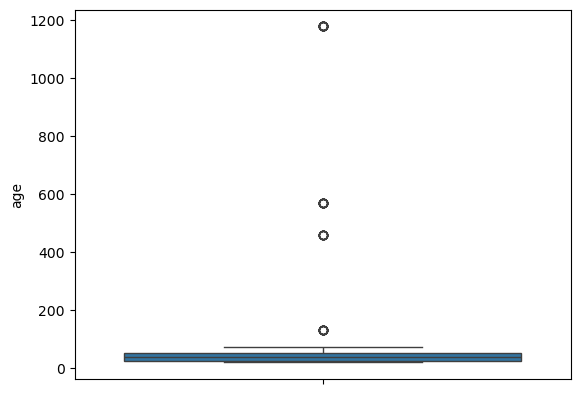

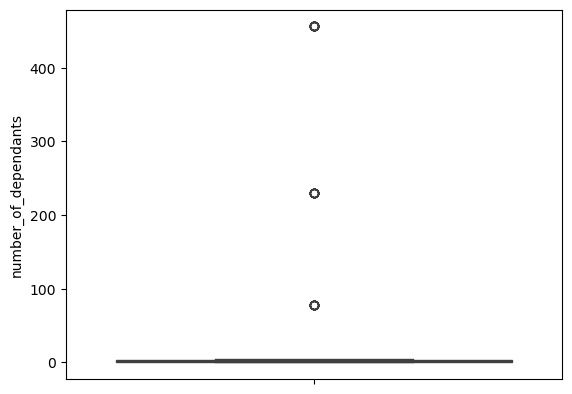

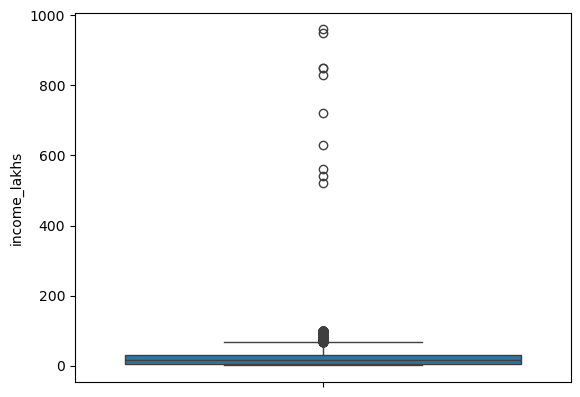

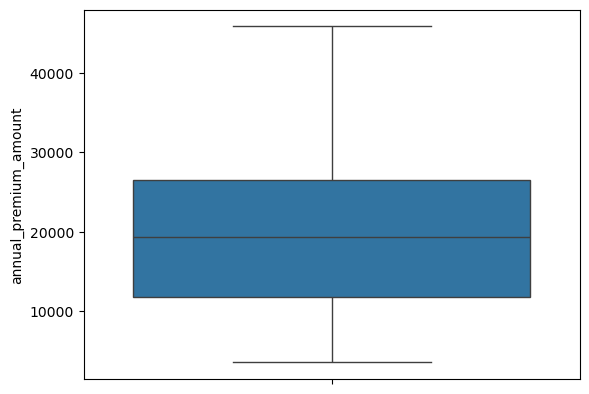

In [274]:
for col in numerical_columns:
    sns.boxplot(df[col])
    plt.show() 


In [275]:
#Outlier treatment
df['age'].describe()

count    10000.000000
mean        41.316300
std         57.971661
min         18.000000
25%         24.000000
50%         37.000000
75%         50.000000
max       1178.000000
Name: age, dtype: float64

In [276]:
df['age'] = df[df['age'] < 100]['age']

In [277]:
df['age'].describe()

count    9942.000000
mean       37.750251
std        13.979445
min        18.000000
25%        24.000000
50%        37.000000
75%        50.000000
max        72.000000
Name: age, dtype: float64

In [278]:
df['income_lakhs'].describe()

count    10000.000000
mean        23.339900
std         32.302974
min          1.000000
25%          6.000000
50%         16.000000
75%         31.000000
max        960.000000
Name: income_lakhs, dtype: float64

In [279]:
df['income_lakhs'] = df[df['income_lakhs'] < 100] ['income_lakhs']

In [280]:
numerical_columns

Index(['age', 'number_of_dependants', 'income_lakhs', 'annual_premium_amount'], dtype='object')

In [281]:
df['income_lakhs'].describe()

count    9960.000000
mean       22.388454
std        22.045258
min         1.000000
25%         6.000000
50%        16.000000
75%        31.000000
max        99.000000
Name: income_lakhs, dtype: float64

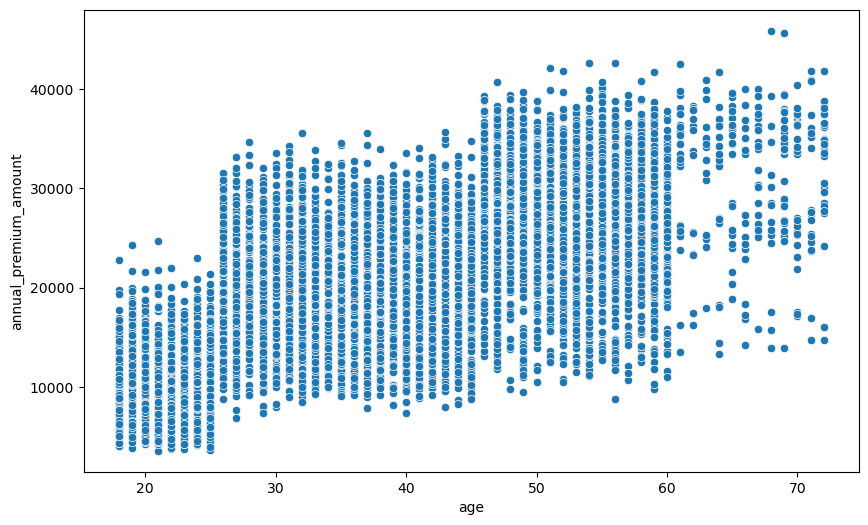

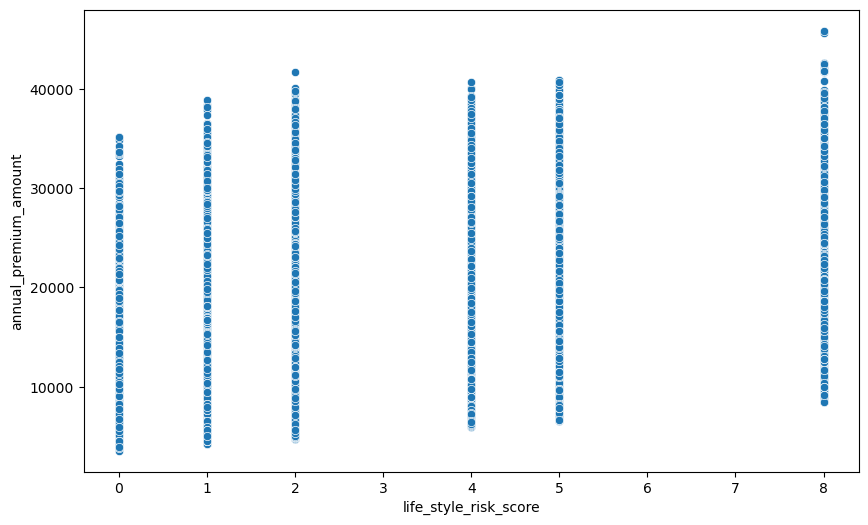

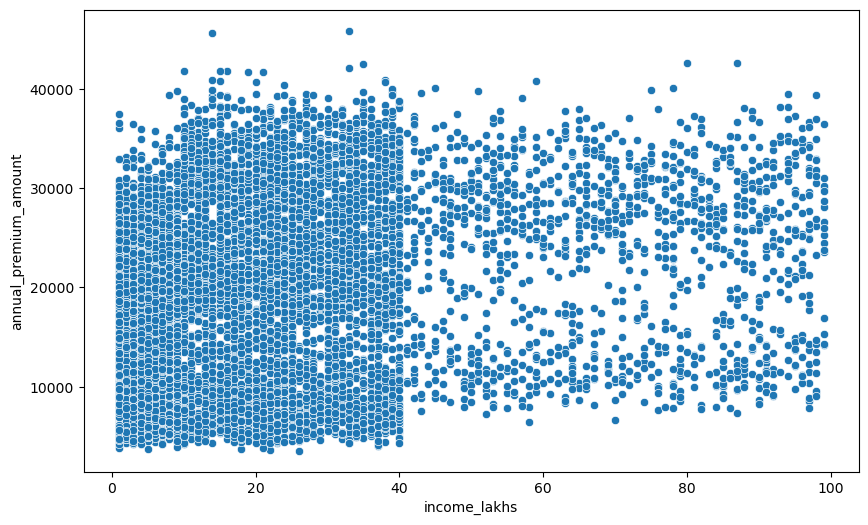

In [282]:
#bi variate analysisabs
plt.figure(figsize= (10, 6))
sns.scatterplot(df, x = df['age'], y = df['annual_premium_amount']) 
plt.show()

plt.figure(figsize= (10, 6))
sns.scatterplot(df, x = df['life_style_risk_score'], y = df['annual_premium_amount']) 
plt.show()


plt.figure(figsize= (10, 6))
sns.scatterplot(df, x = df['income_lakhs'], y = df['annual_premium_amount']) 
plt.show()

In [283]:
## categorical columns analysis


text_columns

Index(['gender', 'region', 'marital_status', 'physical_activity',
       'stress_level', 'bmi_category', 'medical_history', 'insurance_plan'],
      dtype='object')

In [284]:
df = df.drop(axis=1, columns=[('disease1', 'disease2')])

In [285]:
df.columns

Index(['age', 'gender', 'region', 'marital_status', 'physical_activity',
       'stress_level', 'number_of_dependants', 'bmi_category', 'income_lakhs',
       'medical_history', 'insurance_plan', 'annual_premium_amount',
       'life_style_risk_score'],
      dtype='object')

In [286]:
categorical_cols = df.select_dtypes(include= ['object']).columns

In [287]:
categorical_cols

Index(['gender', 'region', 'marital_status', 'bmi_category', 'medical_history',
       'insurance_plan'],
      dtype='object')

In [288]:
df['medical_history'].unique()

array(['High blood pressure', 'No Disease', 'Thyroid',
       'High blood pressure & Heart disease', 'Diabetes & Thyroid',
       'Diabetes', 'Heart disease', 'Diabetes & High blood pressure',
       'Diabetes & Heart disease'], dtype=object)

In [289]:
df[['disease1', 'disease2']] = df['medical_history'].str.split('&', expand=True).apply(lambda x : x.str.lower())
df['disease1'].fillna('none', inplace = True)
df['disease2'].fillna('none', inplace = True)
df[['disease1', 'disease2']]

/var/folders/8_/w3lg606j46ngjff4zhv5f0pm0000gn/T/ipykernel_50534/2524253274.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['disease1'].fillna('none', inplace = True)
/var/folders/8_/w3lg606j46ngjff4zhv5f0pm0000gn/T/ipykernel_50534/2524253274.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always 

,disease1,disease2
0,high blood pressure,none
1,no disease,none
2,no disease,none
3,thyroid,none
4,high blood pressure,heart disease
...,...,...
9995,diabetes,none
9996,high blood pressure,none
9997,no disease,none
9998,diabetes,none


In [290]:
risk_scores = {
    "diabetes": 6,
    "heart disease": 8,
    "high blood pressure":6,
    "thyroid": 5,
    "no disease": 0,
    "none":0
}
df['total_score'] = 0

for disease in ['disease1', 'disease2']:
    df['total_score'] += df[disease].map(risk_scores)

max_score = df['total_score'].max() 
min_score = df['total_score'].min() 

df['normalized_score'] = df['total_score'] - min_score / max_score - min_score

df['normalized_score']

    

0       6.0
1       0.0
2       0.0
3       5.0
4       NaN
       ... 
9995    6.0
9996    6.0
9997    0.0
9998    6.0
9999    5.0
Name: normalized_score, Length: 10000, dtype: float64

In [291]:
df['normalized_score'].fillna(0.0)

0       6.0
1       0.0
2       0.0
3       5.0
4       0.0
       ... 
9995    6.0
9996    6.0
9997    0.0
9998    6.0
9999    5.0
Name: normalized_score, Length: 10000, dtype: float64

In [292]:
df['insurance_plan'] = df['insurance_plan'].map({'Bronze': 1, 'Silver': 2, 'Gold': 3})

In [293]:
df.select_dtypes(include= ['object']).columns

Index(['gender', 'region', 'marital_status', 'bmi_category', 'medical_history',
       'disease1', 'disease2'],
      dtype='object')

In [294]:
df = df.drop(axis=1, columns = ['disease1', 'disease2', 'medical_history'])

In [295]:
df = pd.get_dummies(df, columns=['gender', 'region', 'marital_status', 'bmi_category'], drop_first=True)

In [296]:
df.describe()

,age,physical_activity,stress_level,number_of_dependants,income_lakhs,insurance_plan,annual_premium_amount,life_style_risk_score,total_score,normalized_score
count,9942.000000,10000.000000,10000.000000,10000.000000,9960.000000,10000.000000,10000.000000,10000.000000,9010.000000,9010.000000
mean,37.750251,1.553700,1.708100,3.192900,22.388454,1.892100,19505.063900,3.261800,3.686903,3.686903
std,13.979445,1.466946,1.556643,21.650454,22.045258,0.790392,8893.649171,2.144183,2.984248,2.984248
min,18.000000,0.000000,0.000000,0.000000,1.000000,1.000000,3582.000000,0.000000,0.000000,0.000000
25%,24.000000,1.000000,1.000000,0.000000,6.000000,1.000000,11777.750000,2.000000,0.000000,0.000000
50%,37.000000,1.000000,1.000000,2.000000,16.000000,2.000000,19312.000000,2.000000,5.000000,5.000000
75%,50.000000,4.000000,4.000000,3.000000,31.000000,3.000000,26494.500000,5.000000,6.000000,6.000000
max,72.000000,4.000000,4.000000,456.000000,99.000000,3.000000,45854.000000,8.000000,8.000000,8.000000


In [297]:
df.sample(10)

,age,physical_activity,stress_level,number_of_dependants,income_lakhs,insurance_plan,annual_premium_amount,life_style_risk_score,total_score,normalized_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight
5377,28.0,0,1,2,24.0,2,20669,1,6.0,6.0,True,False,True,False,False,False,True,False
2181,33.0,4,1,3,36.0,2,24791,5,6.0,6.0,True,False,True,False,False,False,True,False
7445,58.0,1,0,3,68.0,3,29845,1,6.0,6.0,False,True,False,False,False,False,True,False
1844,38.0,0,4,4,1.0,1,10173,4,0.0,0.0,False,False,True,False,False,False,False,False
1913,20.0,4,1,2,14.0,3,14708,5,0.0,0.0,False,False,False,True,True,False,False,False
8089,22.0,1,0,0,39.0,1,5509,1,0.0,0.0,True,False,False,True,True,False,False,False
7902,49.0,4,0,2,1.0,3,36518,4,NaN,NaN,False,False,False,True,False,True,False,False
5201,45.0,1,4,0,9.0,1,20078,5,6.0,6.0,False,False,True,False,True,True,False,False
462,56.0,1,1,2,2.0,1,12318,2,6.0,6.0,True,False,True,False,True,False,False,False
2132,48.0,1,4,4,2.0,2,22631,5,6.0,6.0,False,False,False,False,False,False,False,True


In [298]:
cm = df.corr()

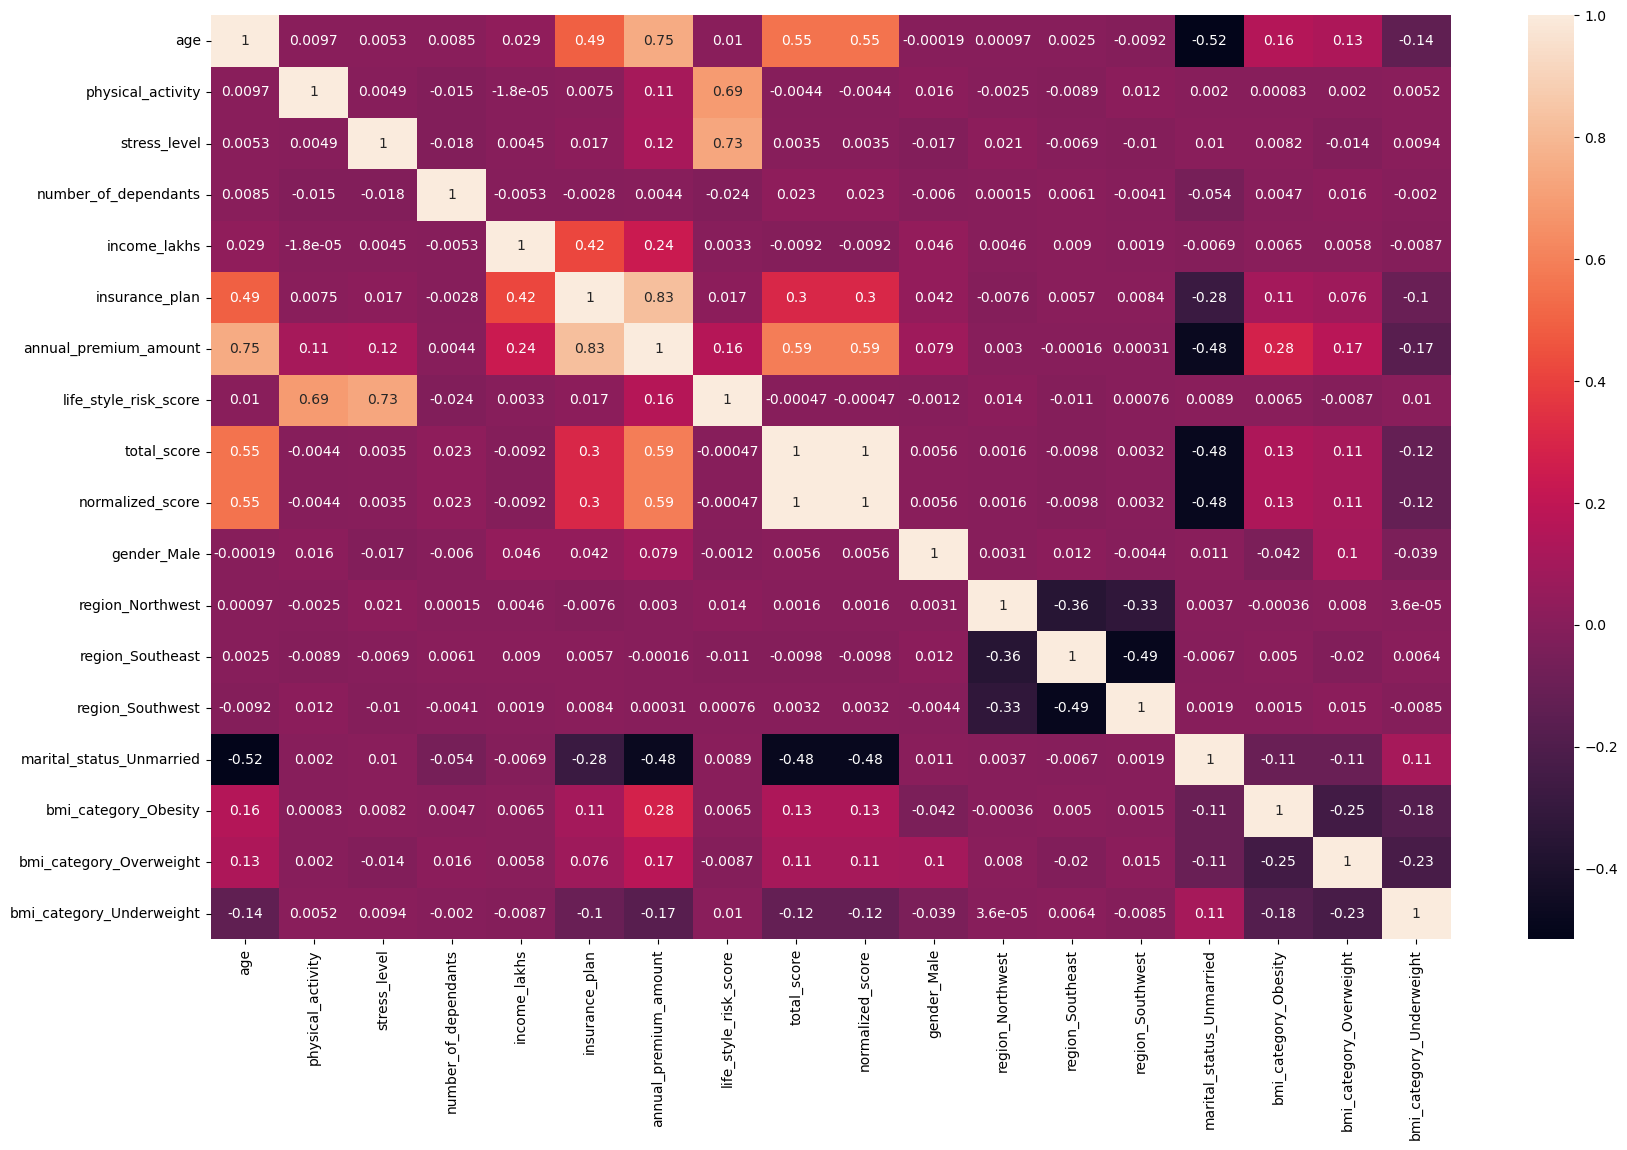

In [299]:
plt.figure(figsize=(20, 12))
sns.heatmap(cm, annot= True)
plt.show()

In [300]:
df.isnull().sum()


age                          58
physical_activity             0
stress_level                  0
number_of_dependants          0
income_lakhs                 40
insurance_plan                0
annual_premium_amount         0
life_style_risk_score         0
total_score                 990
normalized_score            990
gender_Male                   0
region_Northwest              0
region_Southeast              0
region_Southwest              0
marital_status_Unmarried      0
bmi_category_Obesity          0
bmi_category_Overweight       0
bmi_category_Underweight      0
dtype: int64

In [301]:
df['normalized_score'].unique()

array([ 6.,  0.,  5., nan,  8.])

In [302]:
df['total_score'] = df['total_score'].fillna(0.0)

In [246]:
df['total_score'].unique()

array([6., 0., 5., 8.])

In [334]:
df['income_lakhs'] = df['income_lakhs'].fillna(df['income_lakhs'].mean())

df['normalized_score'] = df['normalized_score'].fillna(df['normalized_score'].mean())
df.describe()
df['age'] = df['age'].fillna(df['age'].mean())
df['age'].unique()

array([56.        , 38.        , 18.        , 55.        , 22.        ,
       33.        , 53.        , 39.        , 42.        , 44.        ,
       27.        , 43.        , 30.        , 31.        , 48.        ,
       37.        , 20.        , 45.        , 60.        , 21.        ,
       40.        , 54.        , 23.        , 29.        , 58.        ,
       49.        , 26.        , 28.        , 52.        , 25.        ,
       46.        , 50.        , 19.        , 47.        , 59.        ,
       70.        , 51.        , 24.        , 32.        , 37.75025146,
       41.        , 34.        , 61.        , 57.        , 36.        ,
       68.        , 64.        , 66.        , 72.        , 35.        ,
       71.        , 67.        , 62.        , 69.        , 65.        ,
       63.        ])

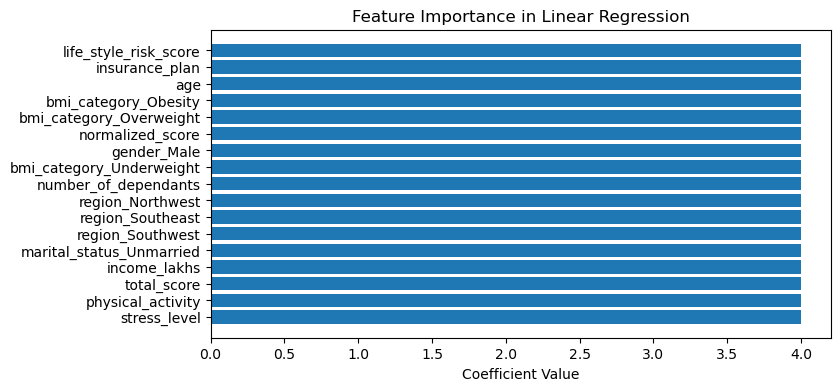

In [348]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score 
from sklearn.preprocessing import MinMaxScaler

X = df.drop(axis= 1, columns=['annual_premium_amount'])
y = df['annual_premium_amount']


cols_to_scale = ['age','number_of_dependants',  'income_lakhs', 'insurance_plan', 'life_style_risk_score']
scaler = MinMaxScaler()

X[cols_to_scale] = scaler.fit_transform(X[cols_to_scale])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42) 

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

model.score(X_train, y_train), model.score(X_test, y_test)

feature_importance = model.coef_
coeff_df = pd.DataFrame(feature_importance, index = X_train.columns, columns= ['Coefficient'])
coeff_df = coeff_df.sort_values(ascending=True, by = 'Coefficient')
coeff_df

plt.figure(figsize= (8, 4))
plt.barh(data = coeff_df['Coefficient'], y = coeff_df.index, width= 4)
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Linear Regression')
plt.show()

In [355]:
from xgboost import XGBRegressor
xgb_model = XGBRegressor() 
xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_model.score(X_train, y_train), xgb_model.score(X_test, y_test)
xgb_model.feature_importances_

array([0.18931468, 0.0017557 , 0.00150469, 0.00118048, 0.00127375,
       0.64219695, 0.01992129, 0.01978523, 0.05006219, 0.00604443,
       0.00092684, 0.00109421, 0.00117271, 0.00118377, 0.04343524,
       0.0173903 , 0.00175744], dtype=float32)

In [356]:
from sklearn.model_selection import RandomizedSearchCV

params = {
'n_estimator': [20, 30 ,40, 50],
'learning_rate': [0.1, 0.2, 0.11, 0.22],
'max_dept': [3, 4, 5, 5]   
}

rsv = RandomizedSearchCV(xgb_model, params, cv =3, n_iter= 10, n_jobs=-1) 
rsv.fit(X_train, y_train)
rsv.best_score_, rsv.best_params_, rsv.best_estimator_

best_model = rsv.best_estimator_

best_model.feature_importances_

/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [15:22:09] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1748292887431/work/src/learner.cc:738: 
Parameters: { "max_dept", "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [15:22:09] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1748292887431/work/src/learner.cc:738: 
Parameters: { "max_dept", "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [15:22:09] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1748292887431/work/src/learner.cc:738: 
Parameters: { "max_dept", "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [15:22:09] WARNING: /Users/runner/miniforg

array([0.22701944, 0.00180644, 0.00141029, 0.00084601, 0.00087489,
       0.6602383 , 0.0152553 , 0.01503429, 0.03074558, 0.00507017,
       0.00073814, 0.0008568 , 0.00075845, 0.00093462, 0.02445628,
       0.01241692, 0.00153808], dtype=float32)

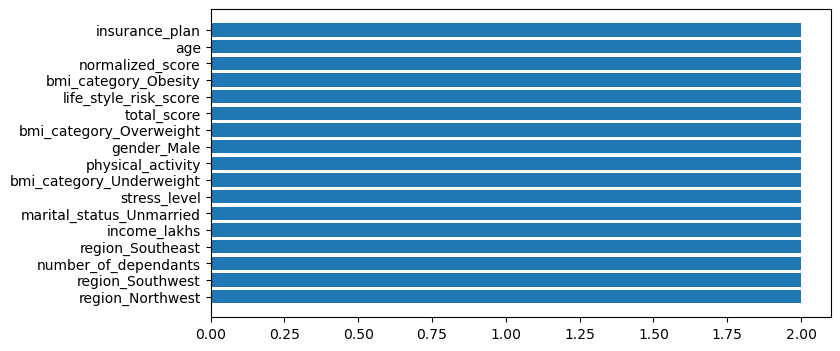

In [364]:
feature_importance = best_model.feature_importances_
feature_df = pd.DataFrame(feature_importance, index = X_train.columns, columns = ['feature_importance'])
feature_df = feature_df.sort_values(ascending=True, by = 'feature_importance')

plt.figure(figsize= (8, 4))
plt.barh(y = feature_df.index, data = feature_df['feature_importance'], width= 2)
plt.show() 


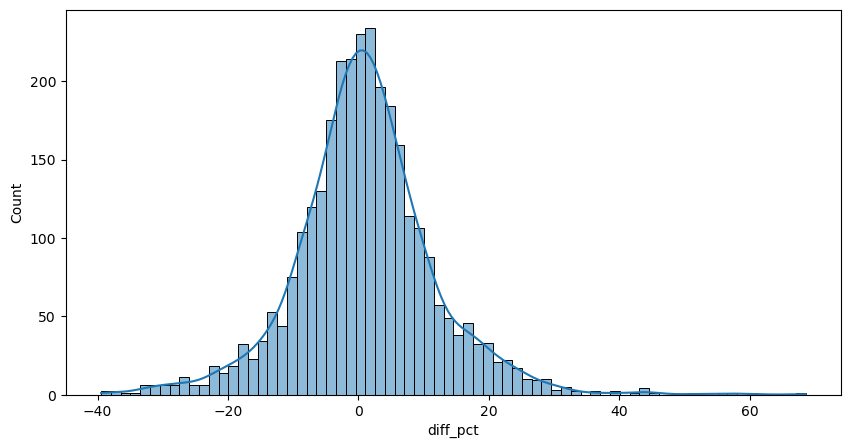

In [373]:

residual = xgb_pred - y_test
rc_pct = (residual / y_test ) *100

residual_df = pd.DataFrame(
    {'actual': y_test, 
     'predicted': xgb_pred, 
     'diff': residual,
     'diff_pct': rc_pct
    }
)

plt.figure(figsize= (10, 5))
sns.histplot(residual_df['diff_pct'], kde=True)
plt.show()

In [379]:
extream_df = residual_df[abs(residual_df['diff_pct']) > 10]['diff_pct']
extream_df.shape, residual_df.shape

((791,), (3000, 4))

In [383]:
extream_df.shape[0]/X_test.shape[0]

0.26366666666666666